In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv("Telecom_customer_churn.csv")

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.drop("customerID",axis=1,inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(22)

In [ ]:
df.drop_duplicates(keep="last",inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   object 
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   object 
 3   Dependents        7021 non-null   object 
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   object 
 6   MultipleLines     7021 non-null   object 
 7   InternetService   7021 non-null   object 
 8   OnlineSecurity    7021 non-null   object 
 9   OnlineBackup      7021 non-null   object 
 10  DeviceProtection  7021 non-null   object 
 11  TechSupport       7021 non-null   object 
 12  StreamingTV       7021 non-null   object 
 13  StreamingMovies   7021 non-null   object 
 14  Contract          7021 non-null   object 
 15  PaperlessBilling  7021 non-null   object 
 16  PaymentMethod     7021 non-null   object 
 17  

In [ ]:
df["TotalCharges"].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      dtype=object)

In [ ]:
df[df["TotalCharges"].isin([" ","NA"," "])==True]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [ ]:
df["TotalCharges"]=df["TotalCharges"].replace(" ",np.nan)

In [ ]:
df["TotalCharges"]=df["TotalCharges"].astype(float)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
Numerical=df.select_dtypes(exclude="object")
Numerical
Categorical=df.select_dtypes(include="object")
Categorical

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,No
7039,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),No
7040,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
7041,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,Yes


In [ ]:
for i in Categorical:
  print(df[i].value_counts())
  print("="*50)

gender
Male      3535
Female    3475
Name: count, dtype: int64
Partner
No     3617
Yes    3393
Name: count, dtype: int64
Dependents
No     4911
Yes    2099
Name: count, dtype: int64
PhoneService
Yes    6330
No      680
Name: count, dtype: int64
MultipleLines
No                  3363
Yes                 2967
No phone service     680
Name: count, dtype: int64
InternetService
Fiber optic    3090
DSL            2414
No             1506
Name: count, dtype: int64
OnlineSecurity
No                     3489
Yes                    2015
No internet service    1506
Name: count, dtype: int64
OnlineBackup
No                     3079
Yes                    2425
No internet service    1506
Name: count, dtype: int64
DeviceProtection
No                     3086
Yes                    2418
No internet service    1506
Name: count, dtype: int64
TechSupport
No                     3464
Yes                    2040
No internet service    1506
Name: count, dtype: int64
StreamingTV
No                     2801
Y

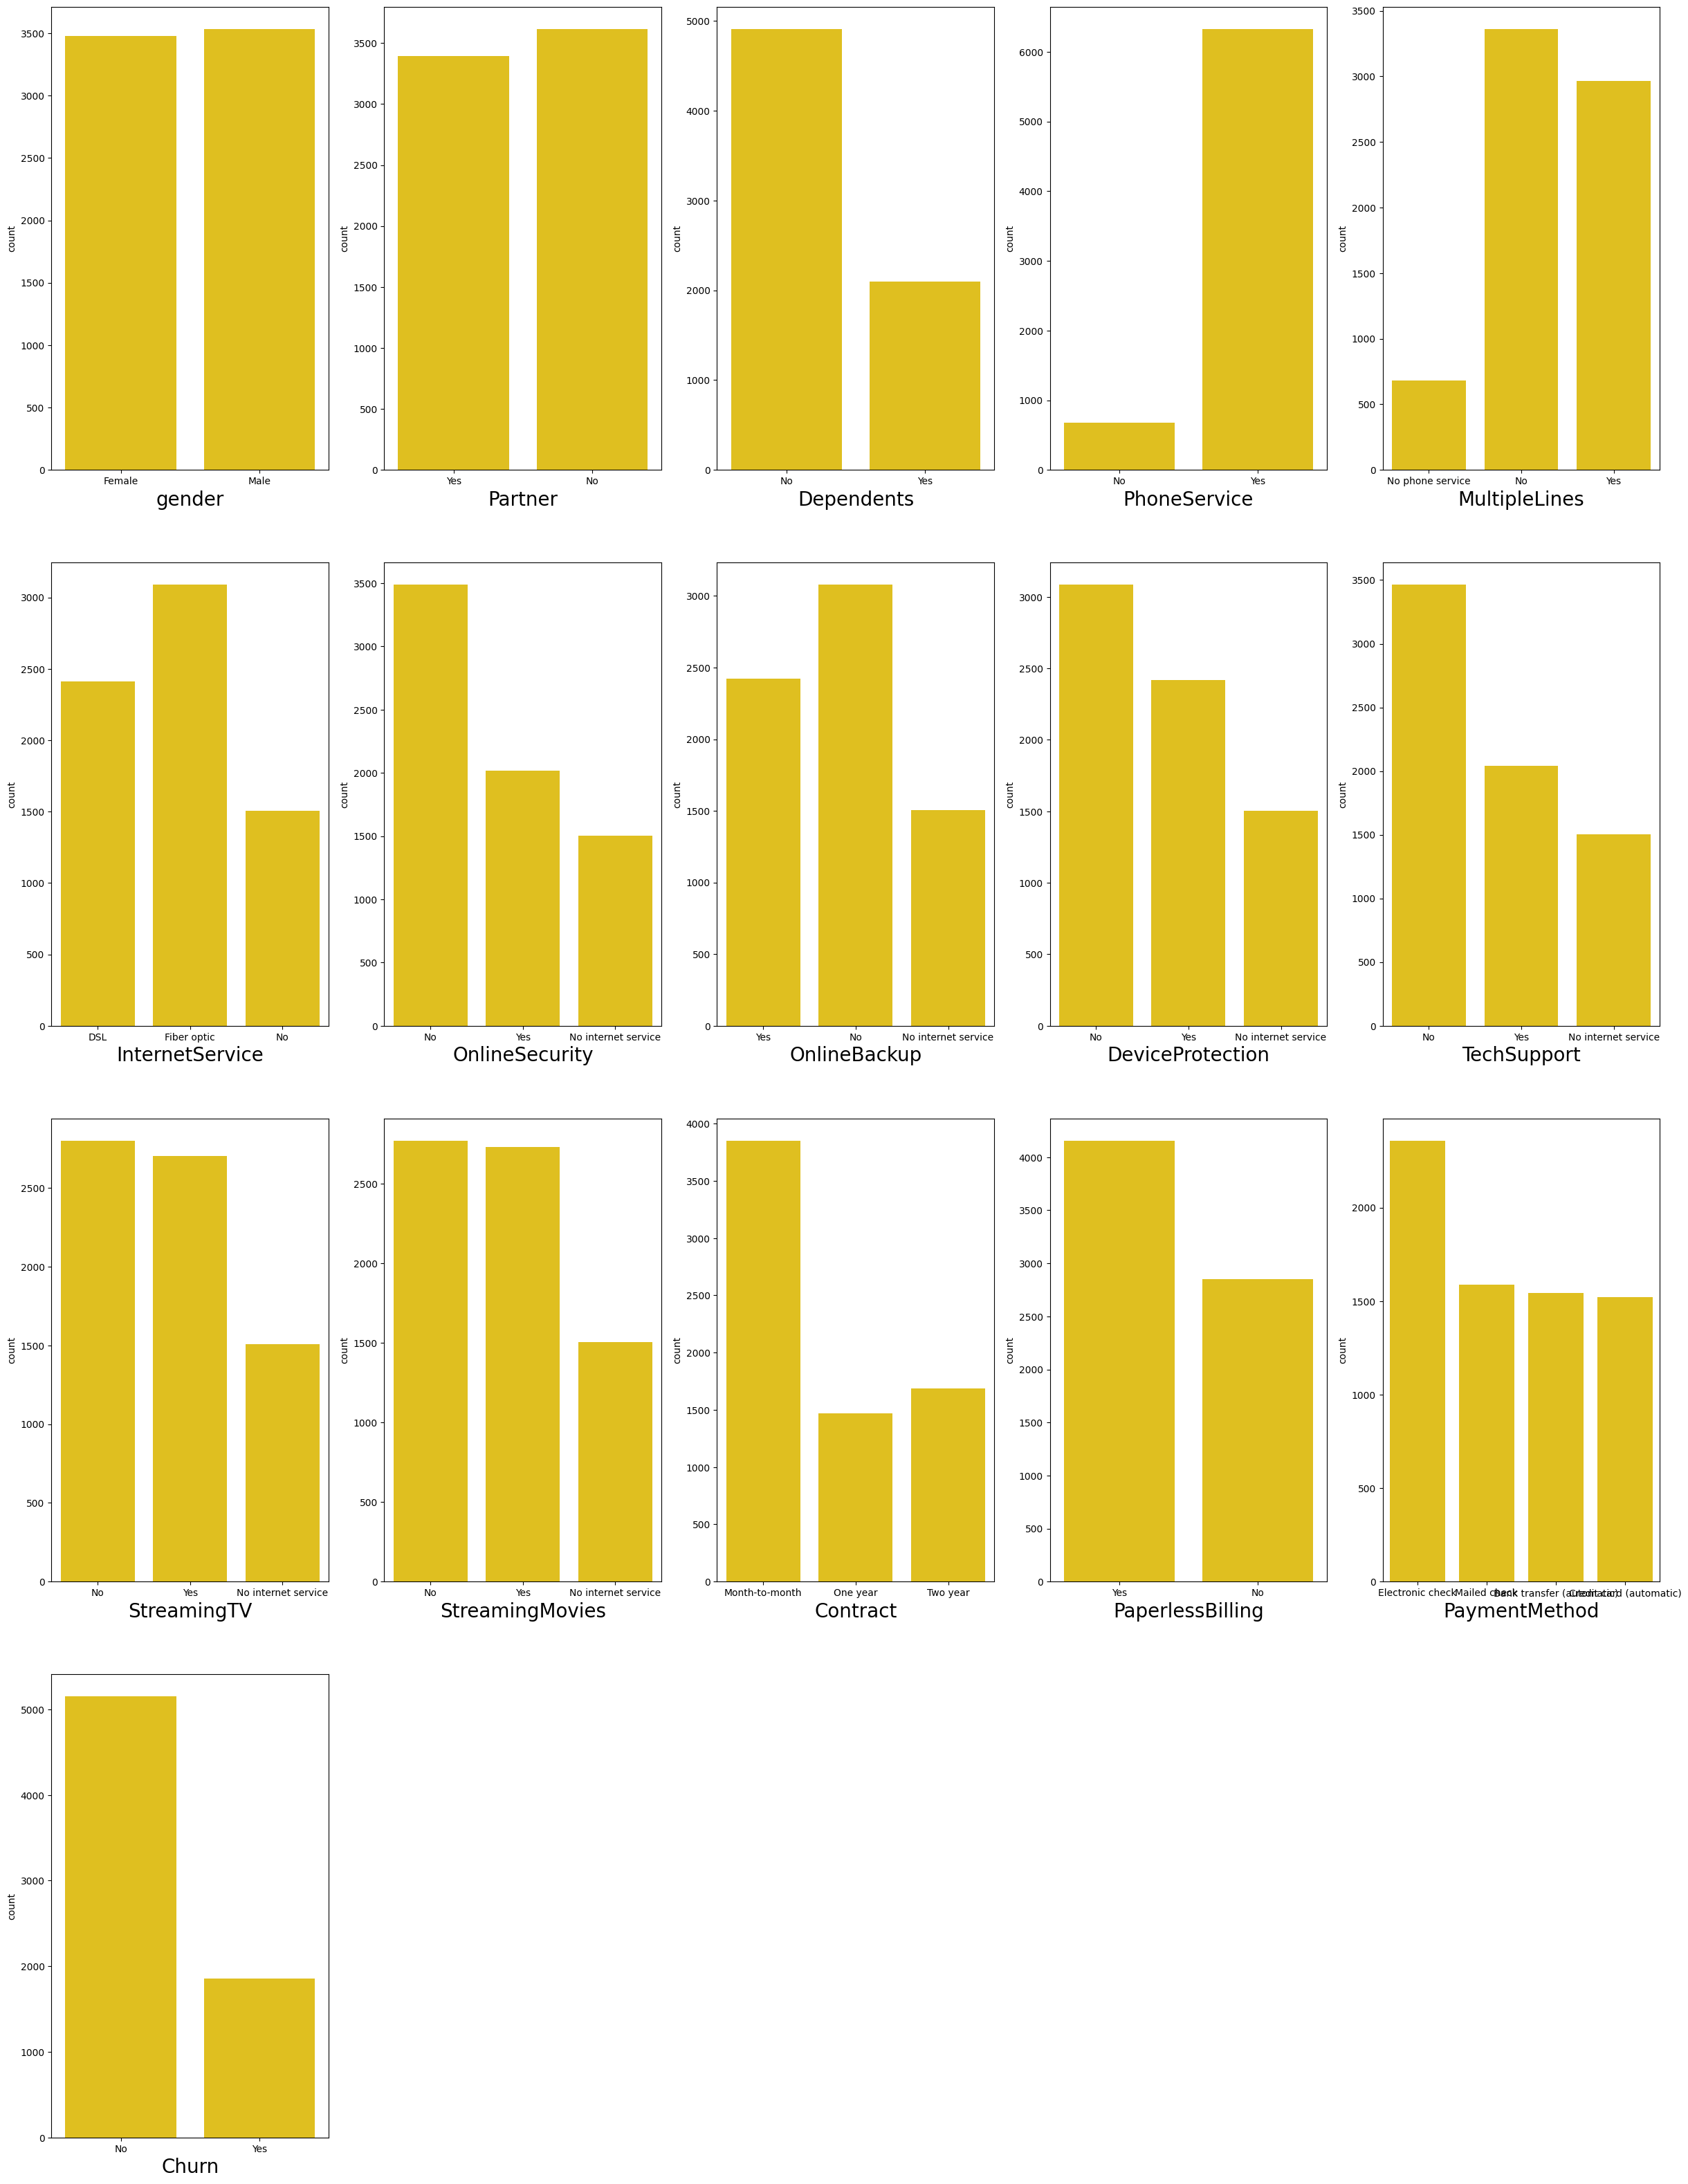

In [ ]:
#import matplotlib.pyplot as plt
sns.set_palette('hsv')
plt.figure(figsize=(30,40), facecolor='white')
plotnumber =1   #i=1
for i in Categorical:
    if plotnumber <=16:
        ax = plt.subplot(4,5,plotnumber)
        sns.countplot(x=df[i])
        plt.xlabel(i,fontsize=20)
    plotnumber+=1
plt.show()

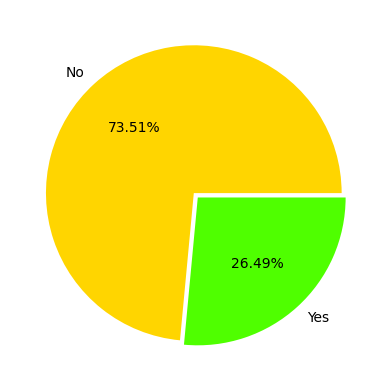

In [ ]:
plt.pie(df["Churn"].value_counts(),
        labels=df["Churn"].value_counts().index,
        autopct="%1.2f%%",
        explode=[0.01,0.03])
plt.show()

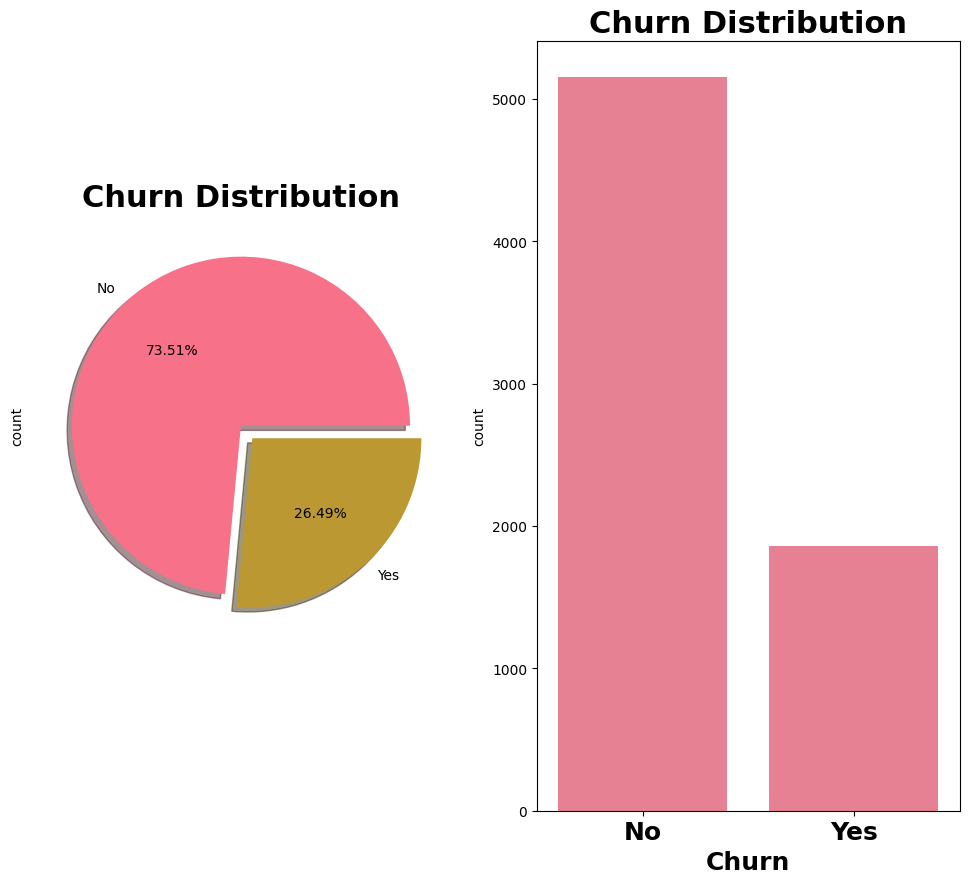

In [ ]:
sns.set_palette('husl')
plt.figure(figsize=(12,10))
plt.subplot(1,2,1)
df['Churn'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.2f%%',shadow=True)
plt.title('Churn Distribution', fontsize=22,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='Churn',data=df)
plt.title('Churn Distribution',fontsize=22,fontweight ='bold')
plt.xlabel("Churn",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=18,fontweight ='bold')
plt.show()

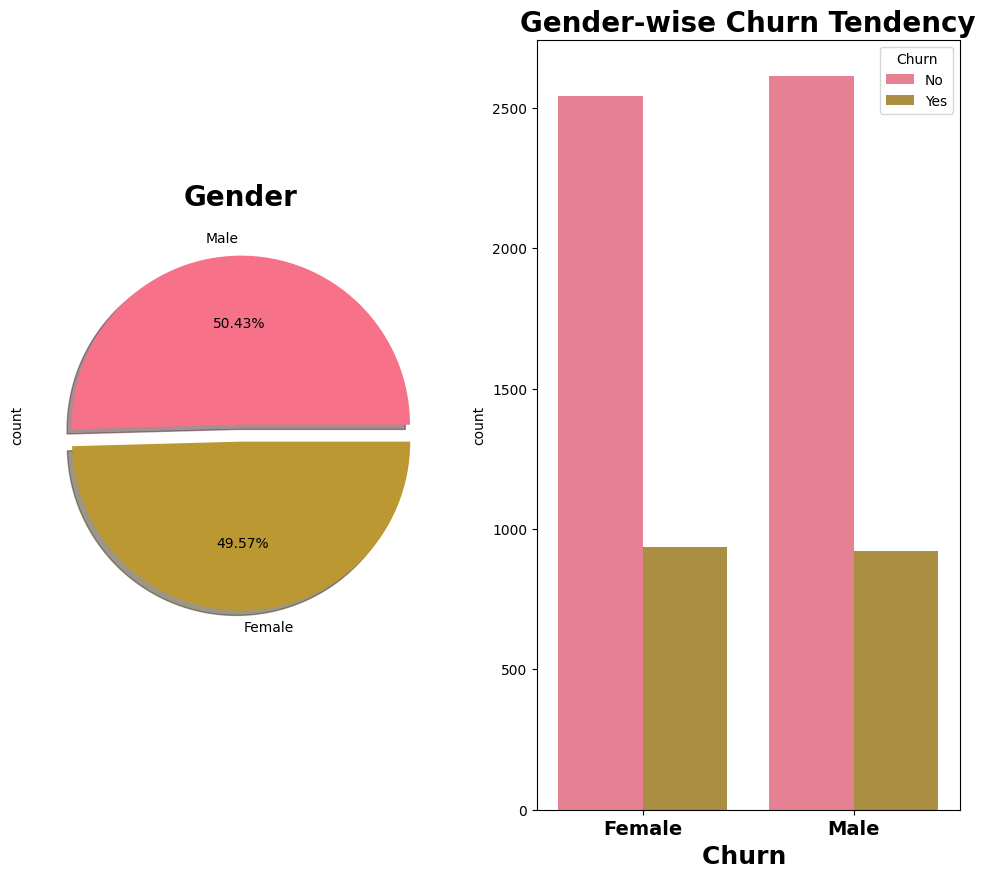

In [ ]:
sns.set_palette('husl')
plt.figure(figsize=(12,10))
plt.subplot(1,2,1)
df['gender'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.2f%%',shadow=True)
plt.title('Gender', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='gender',hue="Churn",data=df)
plt.title('Gender-wise Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("Churn ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.show()

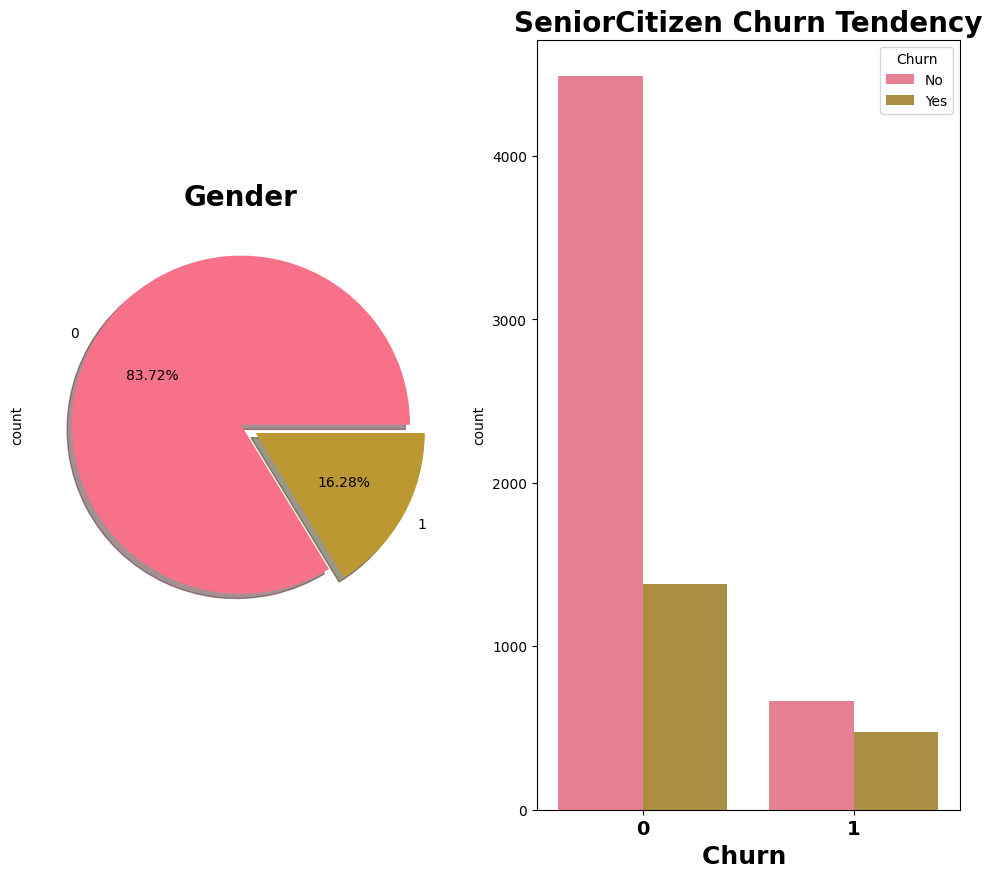

In [ ]:
sns.set_palette('husl')
plt.figure(figsize=(12,10))
plt.subplot(1,2,1)
df['SeniorCitizen'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.2f%%',shadow=True)
plt.title('Gender', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='SeniorCitizen',hue="Churn",data=df)
plt.title('SeniorCitizen Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("Churn ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.show()

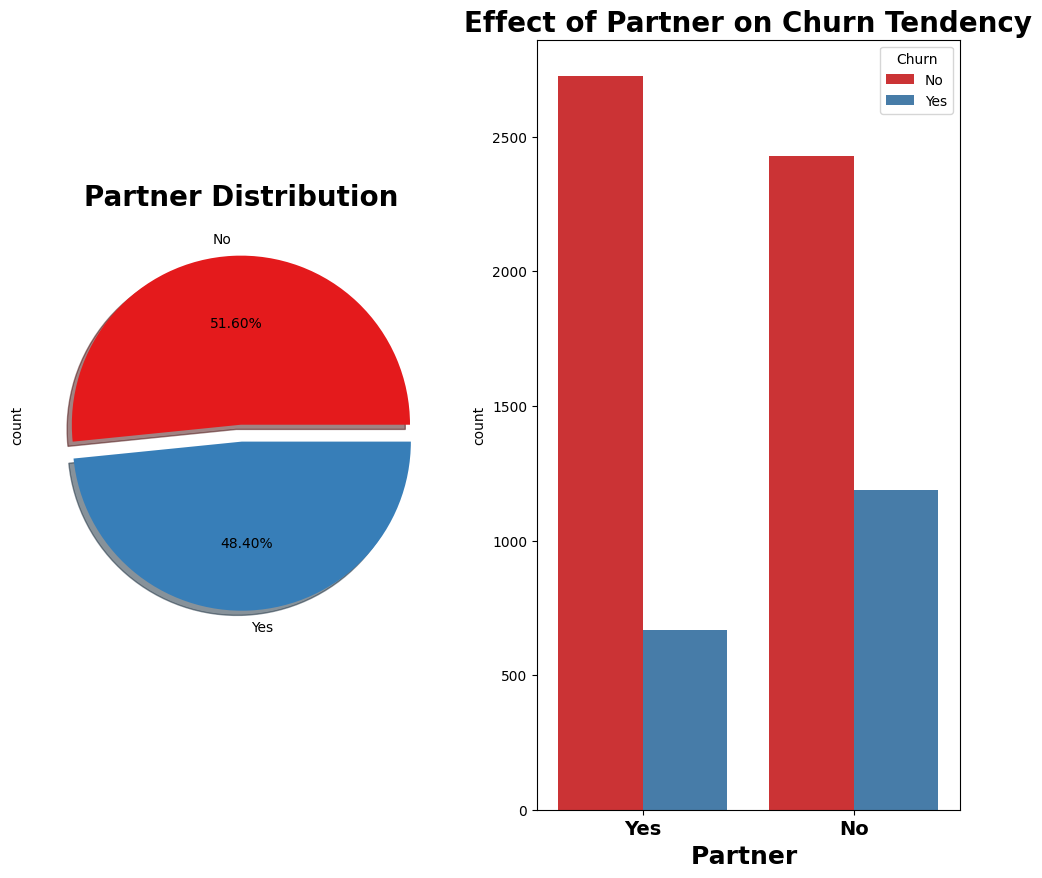

In [ ]:
#Effect of Partner and Dependents on churn
sns.set_palette('Set1')
plt.figure(figsize=(12,10))
plt.subplot(1,2,1)
df['Partner'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.2f%%',shadow=True)
plt.title('Partner Distribution', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='Partner',hue="Churn",data=df)
plt.title('Effect of Partner on Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("Partner ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.show()

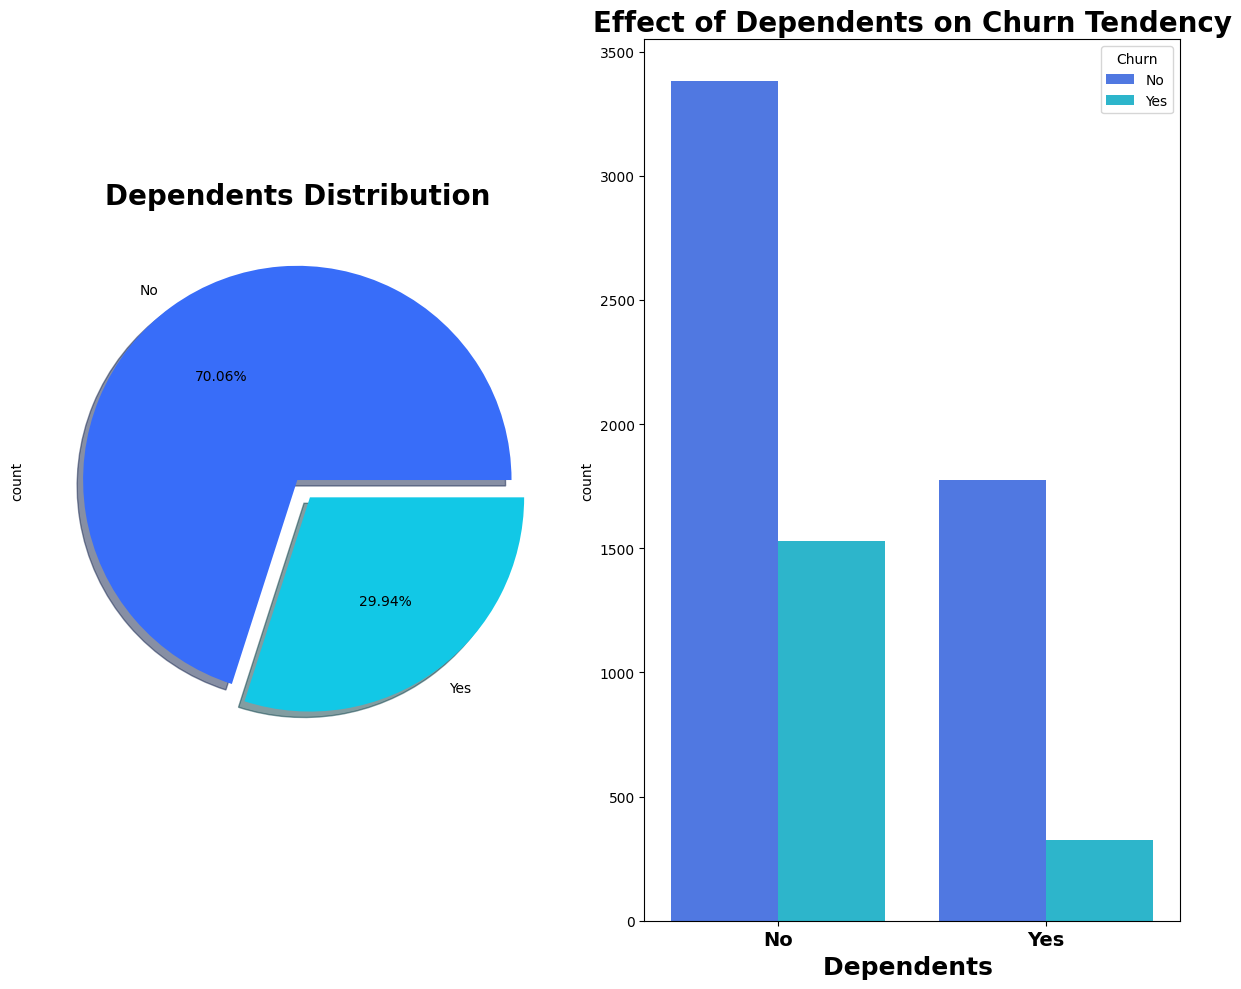

In [ ]:
sns.set_palette('rainbow')
plt.figure(figsize=(12,10))
plt.subplot(1,2,1)
df['Dependents'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.2f%%',shadow=True)
plt.title('Dependents Distribution', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='Dependents',hue="Churn",data=df)
plt.title('Effect of Dependents on Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("Dependents ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.tight_layout()
plt.show()

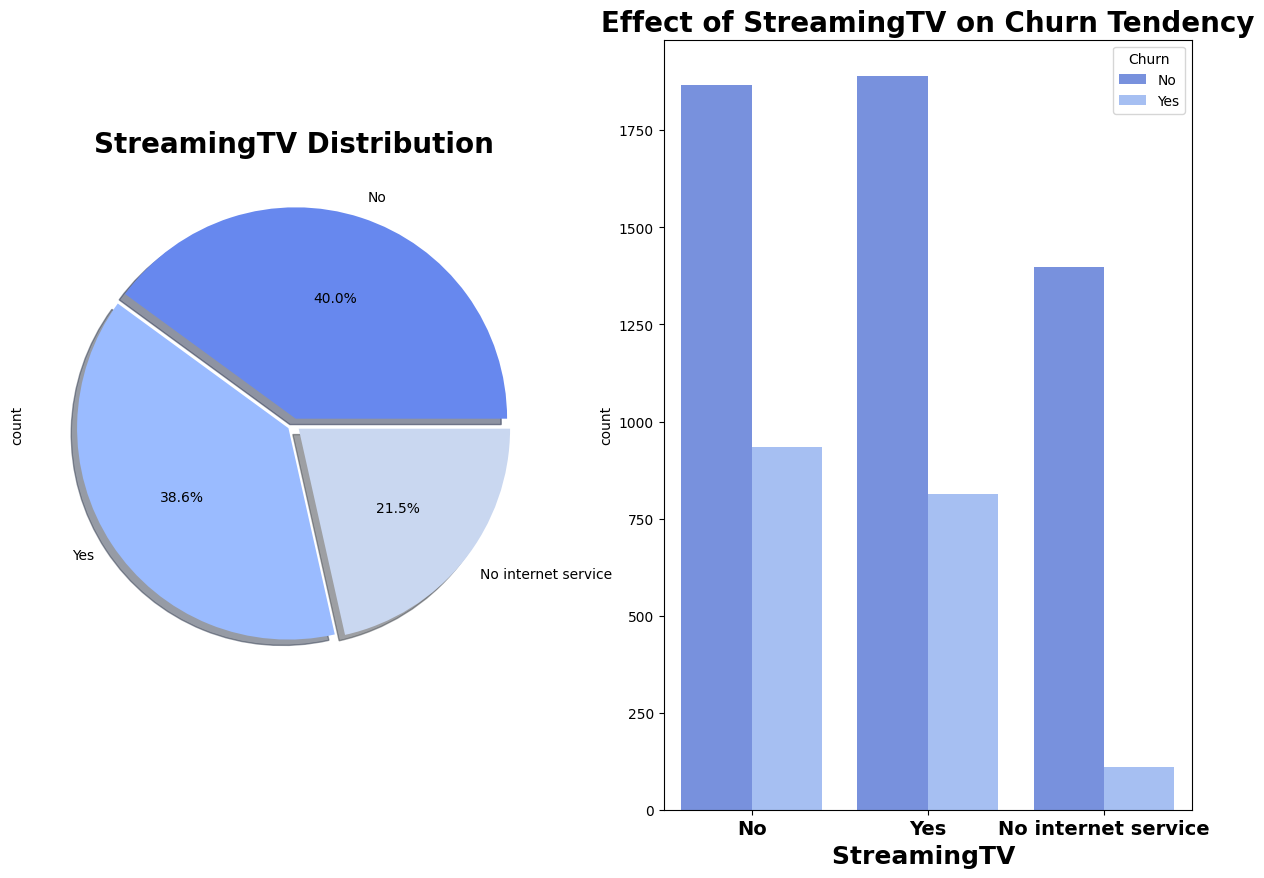

In [ ]:
sns.set_palette('coolwarm')
plt.figure(figsize=(15,10))
plt.subplot(1,2,1)
df['StreamingTV'].value_counts().plot.pie(explode=[0.03,0.03,0.03],autopct='%2.1f%%',shadow=True)
plt.title('StreamingTV Distribution', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='StreamingTV',hue="Churn",data=df)
plt.title('Effect of StreamingTV on Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("StreamingTV ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.show()

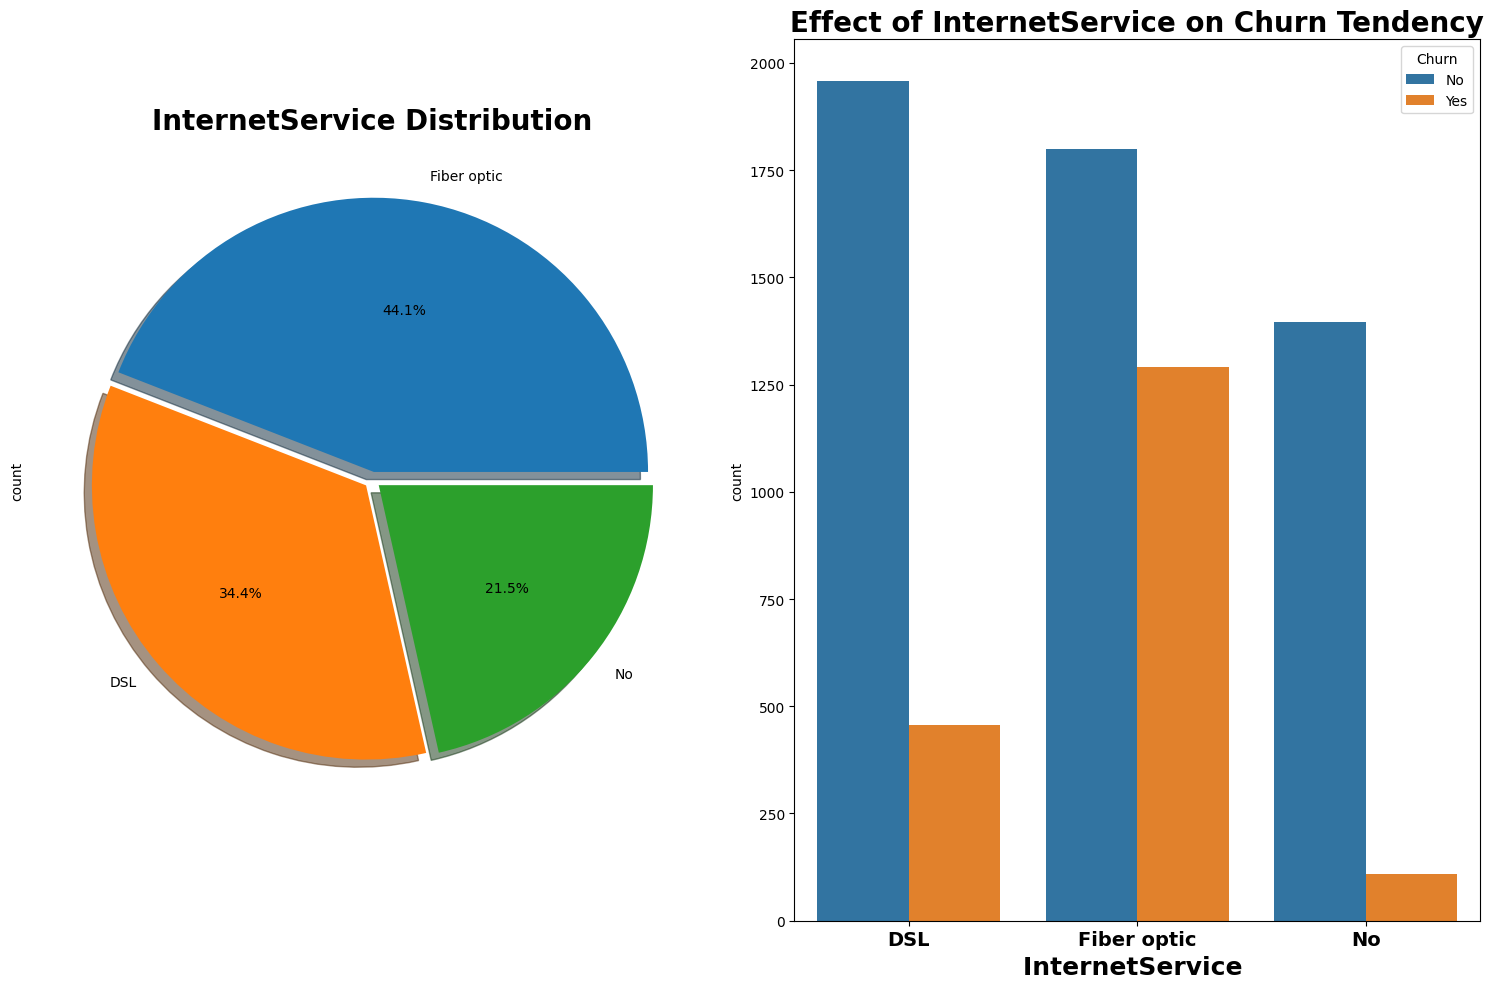

In [ ]:
#Effect of Internet Service
sns.set_palette('tab10')
plt.figure(figsize=(15,10))
plt.subplot(1,2,1)
df['InternetService'].value_counts().plot.pie(explode=[0.03,0.03,0.03],autopct='%2.1f%%',shadow=True)
plt.title('InternetService Distribution', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='InternetService',hue="Churn",data=df)
plt.title('Effect of InternetService on Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("InternetService ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.tight_layout()
plt.show()

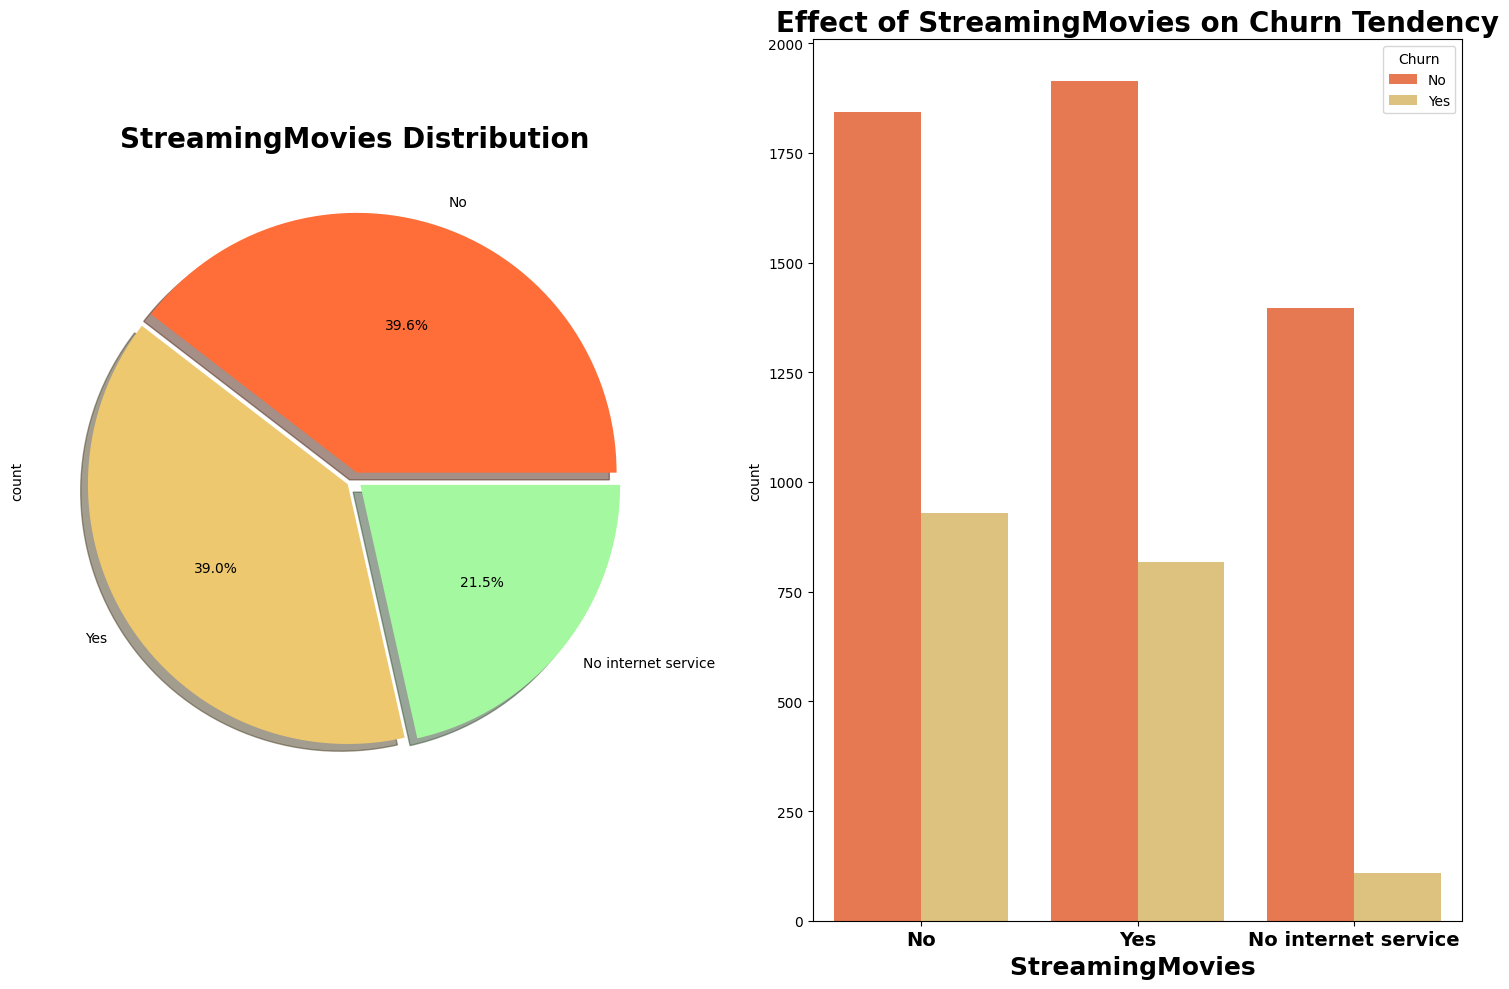

In [ ]:
sns.set_palette('rainbow_r')
plt.figure(figsize=(15,10))
plt.subplot(1,2,1)
df['StreamingMovies'].value_counts().plot.pie(explode=[0.03,0.03,0.03],autopct='%2.1f%%',shadow=True)
plt.title('StreamingMovies Distribution', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='StreamingMovies',hue="Churn",data=df)
plt.title('Effect of StreamingMovies on Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("StreamingMovies ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.tight_layout()
plt.show()

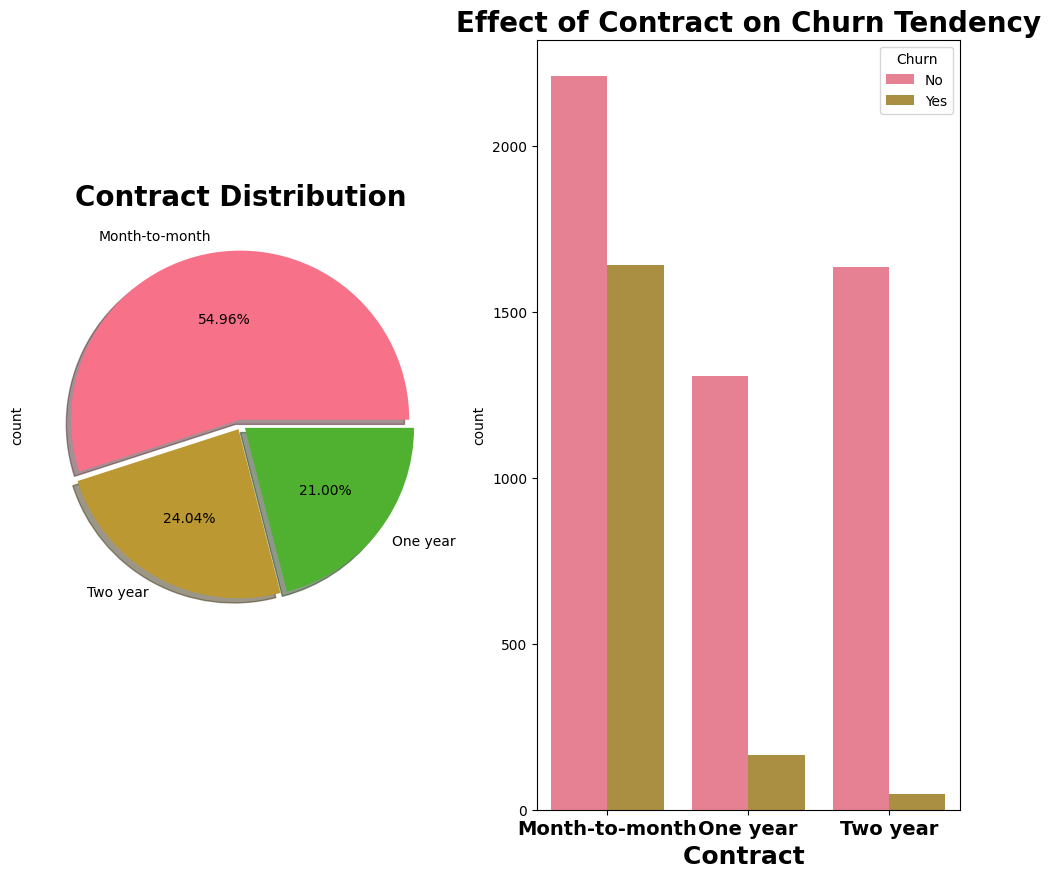

In [ ]:
sns.set_palette('husl')
plt.figure(figsize=(12,10))
plt.subplot(1,2,1)
df['Contract'].value_counts().plot.pie(explode=[0.03,0.03,0.03],autopct='%1.2f%%',shadow=True)
plt.title('Contract Distribution', fontsize=20,fontweight ='bold')
plt.subplot(1,2,2)
sns.countplot(x='Contract',hue="Churn",data=df)
plt.title('Effect of Contract on Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("Contract ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.show()

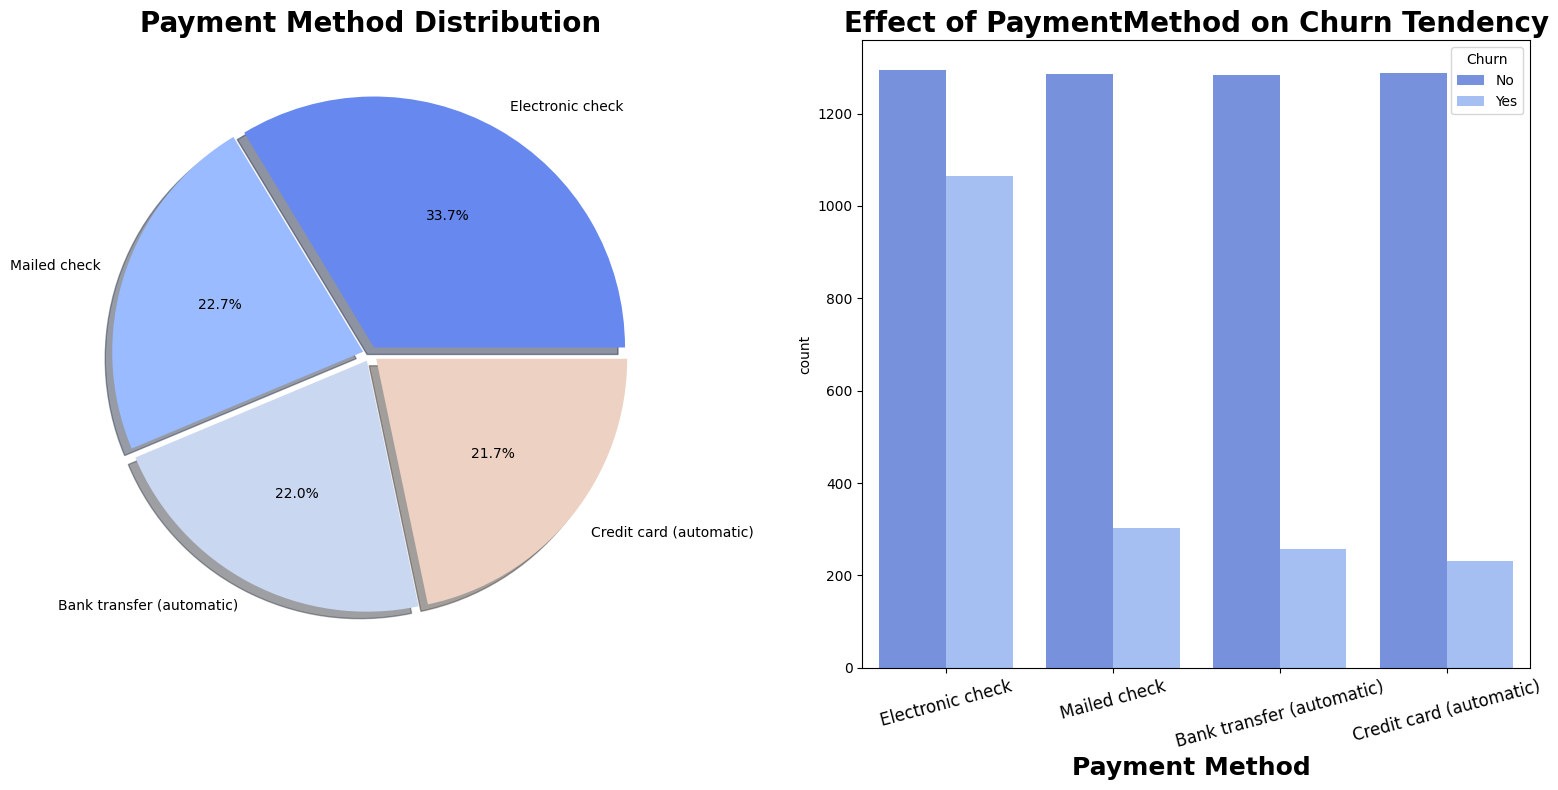

In [ ]:
sns.set_palette('coolwarm')
plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
df['PaymentMethod'].value_counts().plot.pie(explode=[0.03,0.03,0.03,0.03],autopct='%2.1f%%',shadow=True)
plt.title('Payment Method Distribution', fontsize=20,fontweight ='bold')
plt.ylabel('')
plt.subplot(1,2,2)
sns.countplot(x='PaymentMethod',hue="Churn",data=df)
plt.title('Effect of PaymentMethod on Churn Tendency',fontsize=20,fontweight ='bold')
plt.xlabel("Payment Method ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=12,rotation=15)
plt.tight_layout()
plt.show()